In [67]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score,precision_score,f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer


In [68]:
df = pd.read_csv(r"C:\Users\aahan\Self\Coding\Kaggle\credit_card\train.csv")

In [69]:
df.head(10)

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0
5,5,10.74,0.12,4,18.05,51,53,1885.81,0,56.3,...,PIN,ATM,Android Phone,False,False,True,False,False,False,0.0
6,6,20.56,4.99,3,18.07,54,78,769.62,0,15.3,...,3D Secure,Online,POS Terminal,False,False,False,False,False,False,0.0
7,7,38.08,12.08,6,11.53,52,24,4566.46,0,39.5,...,PIN,Online,Android Phone,False,False,False,False,False,False,0.0
8,8,15.06,4.88,5,7.85,47,54,682.02,0,18.5,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
9,9,26.48,3.72,2,1.52,40,27,4973.30,0,9.3,...,Biometric,POS,Android Phone,False,True,False,False,False,False,0.0


In [70]:
df.tail(10)

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
699950,699950,33.34,7.97,1,14.07,46,38,3136.64,0,0.0,...,PIN,Online,Android Phone,False,False,True,False,False,False,0.0
699951,699951,11.22,4.59,3,9.13,44,42,1459.95,0,18.6,...,PIN,POS,Android Phone,False,False,False,False,False,False,0.0
699952,699952,43.97,10.03,3,3.09,44,24,3109.01,0,9.4,...,3D Secure,POS,Android Phone,False,True,False,False,False,True,0.0
699953,699953,22.90,1.42,0,0.59,43,50,799.76,0,15.6,...,OTP,Contactless,Android Phone,False,False,False,False,False,False,0.0
699954,699954,29.11,5.78,1,1.74,47,68,2826.60,0,1.3,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
699955,699955,715.39,4.10,3,3.24,45,31,1598.50,0,20.8,...,3D Secure,POS,Windows PC,False,False,False,False,False,False,0.0
699956,699956,32.28,0.04,6,8.56,44,81,2149.48,1,65.0,...,No Authentication,Online,iPhone,False,False,False,False,False,False,0.0
699957,699957,22.95,4.99,4,4.23,37,69,959.88,0,19.3,...,Biometric,Online,Android Phone,False,False,True,False,False,False,0.0
699958,699958,14.19,1.86,4,28.08,40,72,1362.85,0,31.0,...,PIN,ATM,Windows PC,False,False,True,False,False,False,0.0
699959,699959,36.16,3.51,3,1.53,48,21,2645.98,0,8.9,...,Biometric,Online,Android Phone,False,False,False,False,False,False,0.0


is_fraud
0.0    688271
1.0     11689
Name: count, dtype: int64
Fraud rate: 1.6700%


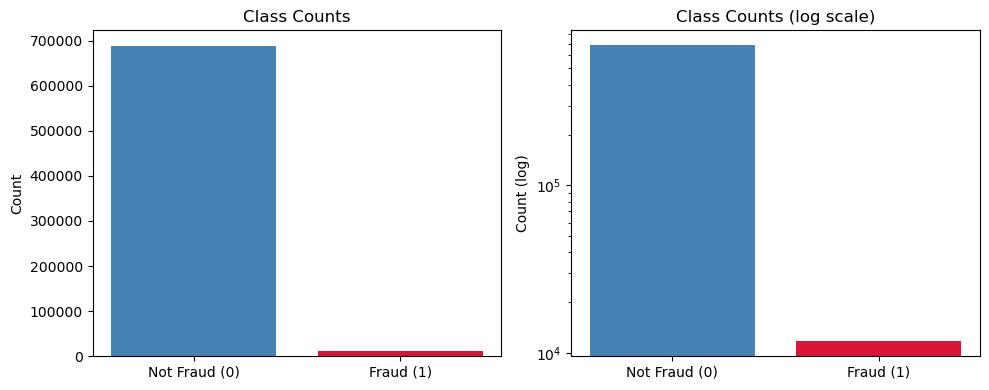

In [71]:
# Count plot
counts = df["is_fraud"].value_counts().sort_index()
print(counts)
print(f"Fraud rate: {counts[1] / counts.sum():.4%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Bar chart (raw counts)
axes[0].bar(["Not Fraud (0)", "Fraud (1)"], counts.values, color=["steelblue", "crimson"])
axes[0].set_title("Class Counts")
axes[0].set_ylabel("Count")

# Log-scale bar chart (so the minority class is visible)
axes[1].bar(["Not Fraud (0)", "Fraud (1)"], counts.values, color=["steelblue", "crimson"])
axes[1].set_yscale("log")
axes[1].set_title("Class Counts (log scale)")
axes[1].set_ylabel("Count (log)")

plt.tight_layout()
plt.show()

In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-nul

In [73]:
X = df.drop(columns=["id", "is_fraud"])
y = df["is_fraud"]

cat_variables = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_variables = X.select_dtypes(include=["number"]).columns.tolist()

In [74]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_variables),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_variables),
])


In [75]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y
)

In [76]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("XGboost", XGBClassifier()),
])

In [77]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('XGboost', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [78]:
val_proba = model.predict_proba(X_val)[:, 1]

In [79]:
print("Validation AUC:", roc_auc_score(y_val, val_proba))

Validation AUC: 0.8926577627722168


In [82]:
test = pd.read_csv('test.csv')
test_ids = test["id"]
X_test = test.drop(columns=["id"])

In [83]:
test_proba = model.predict_proba(X_test)[:, 1]
submission = pd.DataFrame({"id": test_ids, "is_fraud": test_proba})
submission.to_csv("submission.csv", index=False)